#Importing Dataset


In [85]:
import requests
import pandas as pd
#Remember to attach GPU

#Training and Validation Datasets from Twitter
#https://raw.githubusercontent.com/KrishnaRohithVemulapalli/DeepDive-Into-AI-Workshop/main/twitter_training.csv
#https://raw.githubusercontent.com/KrishnaRohithVemulapalli/DeepDive-Into-AI-Workshop/main/twitter_validation.csv


training_data = pd.read_csv("https://raw.githubusercontent.com/KrishnaRohithVemulapalli/DeepDive-Into-AI-Workshop/main/twitter_training.csv")
validation_data = pd.read_csv("https://raw.githubusercontent.com/KrishnaRohithVemulapalli/DeepDive-Into-AI-Workshop/main/twitter_validation.csv")

#Preprocessing:

In [86]:
#Resetting columns
training_data.columns = ["SerialNo", "Company", "Labels", "Text"]
validation_data.columns = ["SerialNo", "Company", "Labels", "Text"]

In [87]:
print(training_data.isnull().sum())
print("*" * 20)
print(validation_data.isnull().sum())

SerialNo      0
Company       0
Labels        0
Text        686
dtype: int64
********************
SerialNo    0
Company     0
Labels      0
Text        0
dtype: int64


In [88]:
print(training_data.duplicated().sum())
print(validation_data.duplicated().sum())

2700
0


In [89]:
#WE have a small validation/testing so lets merge them

sentiment = pd.concat([training_data, validation_data], ignore_index = True)
#Dropping duplicates and removing null values
sentiment.drop_duplicates(inplace = True)
sentiment.dropna(inplace = True)

In [90]:
sentiment["Labels"].unique() #The emotions we are trying to classify

array(['Positive', 'Neutral', 'Negative', 'Irrelevant'], dtype=object)

In [91]:
sentiment.drop(columns = ["SerialNo", "Company"], inplace = True)

# Ex. If Facebook got too many bad reviews, then if you get a good review in Facebook it will classify as negative
# This is why we are not using Company


In [92]:
import numpy as np
import re
import nltk
# Natural Lang Tool Kit
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("wordnet")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [93]:
#lemmatization

import nltk
from nltk.stem import WordNetLemmatizer
l = WordNetLemmatizer()
word = ["running", "ran", "better", "cats", "mouse"]

In [94]:
for w in word:
  lemma = l.lemmatize(w)
  print(lemma)

running
ran
better
cat
mouse


In [95]:
#text Preprocessing
import numpy as np
def process_the_text(text):
  text=re.sub(r'\s+',' ',text, flags=re.I)
  #remove spl characters other than A-Z,a-z,0-9 or _
  text=re.sub(r'\W',' ',text)

  #remove single character
  text=re.sub(r'\s+[a-zA-Z]\s+',' ',text)

  #remove character not alphabetical
  text=re.sub(r'[^a-zA-Z\s]','',text)

  text=text.lower()

  words= word_tokenize(text)

  l = WordNetLemmatizer()
  words=[l.lemmatize(i) for i in words]

  stop=set(stopwords.words('english'))
  Words=[word for word in words if word not in stop]


  Words=[word for word in Words if len(word)>3]

  #removing duplicate words
  indices = np.unique(Words, return_index=True)[1]
  cleaned_text =np.array(Words)[np.sort(indices)].tolist()

  return cleaned_text

In [96]:
x = sentiment.drop("Labels", axis= 1)
y = sentiment.Labels

In [97]:
texts = list(x["Text"])
texts[:5]

['I am coming to the borders and I will kill you all,',
 'im getting on borderlands and i will kill you all,',
 'im coming on borderlands and i will murder you all,',
 'im getting on borderlands 2 and i will murder you me all,',
 'im getting into borderlands and i can murder you all,']

In [98]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
cleaned_texts = [process_the_text(text) for text in texts]

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [99]:
#Now our text is into tokens
print(cleaned_texts[0:10])

[['coming', 'border', 'kill'], ['getting', 'borderland', 'kill'], ['coming', 'borderland', 'murder'], ['getting', 'borderland', 'murder'], ['getting', 'borderland', 'murder'], ['spent', 'hour', 'making', 'something', 'know', 'huge', 'borderland', 'maya', 'favorite', 'character', 'decided', 'make', 'wallpaper', 'original', 'image', 'versus', 'creation', 'made', 'enjoy', 'twitter', 'mlsiwfjg'], ['spent', 'couple', 'hour', 'something', 'know', 'huge', 'borderland', 'maya', 'favorite', 'character', 'decided', 'make', 'wallpaper', 'original', 'picture', 'compared', 'creation', 'made', 'twitter', 'mlsiwfjg'], ['spent', 'hour', 'something', 'know', 'huge', 'borderland', 'maya', 'favorite', 'character'], ['spent', 'hour', 'making', 'something', 'know', 'huge', 'rhandlerr', 'maya', 'favorite', 'character', 'decided', 'make', 'wallpaper', 'original', 'image', 'versus', 'creation', 'made', 'enjoy', 'twitter', 'mlsiwfjg'], ['spent', 'hour', 'making', 'something', 'know', 'huge', 'rhandlerr', 'maya

#Setting up the Model

In [100]:
# We cannot directly feed all of this into RNN, we need to convert to numerals
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(cleaned_texts, y, test_size=0.2)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_vocab = 20000 #Most frequent 20K words
tokenizer = Tokenizer(num_words = max_vocab)
tokenizer.fit_on_texts(x_train)
word_idx = tokenizer.word_index #Word indexes to the words
v = len(word_idx)
print("The size of vocab: " + str(v)) #Corrected spacing

x_train = tokenizer.texts_to_sequences(x_train)
x_test = tokenizer.texts_to_sequences(x_test)

#We put 20K but got 24K because we specified to the Tokenizer that it should handle the initial amt
# However,

The size of vocab: 24130


In [101]:
maxlen = 100
x_test = pad_sequences(x_test, maxlen = maxlen)
x_train = pad_sequences(x_train, maxlen = maxlen)

In [102]:
#architecture
import tensorflow
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.optimizers import Adam


#Learning about Regularization and Model Implementation


In [103]:
#Defining the input layer shape

#FYI all of them are using already set activations


input1 = Input(shape=(maxlen,)) #Maxlen is = to 100

D = 100
#Embedding Layer
embedding_layer = Embedding(v+1, D)(input1) # v+1, D specifies the number of connections to output
# And number of connections to input. First is output, second is number of input connections
drop_layer = Dropout(0.5)(embedding_layer) #Now we will regularize it. Often when you encounter overfitting,


#Bidirectional LSTM (it goes forward and backward)
lstm_layer = Bidirectional(LSTM(150))(drop_layer) #This is 150 neurons
#The drop layer is dropping out half neurons from embedding layer

#Dense layers
dense_layer1 = Dense(32, activation = "relu")(lstm_layer) # For first we can set, for others it will set itself
#Make sure hidden layers is RELU, but don't use in Output
output_layer = Dense(4, activation="softmax")(dense_layer1) #Just refers to last layer

model = Model(input1, output_layer) #Model Created.






In [104]:
#We haven't encoded the labels of Y which wil make model more easier to run so lets do that


from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)


#But we still have another problem:
#We are using categorical crossentropy which likes 0 and 1. So we should change it to One Hot Encoding
import tensorflow as tf

y_train_onehot=tf.keras.utils.to_categorical(y_train)
y_test_onehot=tf.keras.utils.to_categorical(y_test)


In [105]:
#Optimization is a bunch of mathematical functions that speeds Backpropogation
#Custom Optimizer
learning_rate = 0.0001
optimizer = Adam(learning_rate)

#We haven't encoded the labels of Y yet so let's do that first

model.compile(optimizer= optimizer, loss = "categorical_crossentropy", metrics = ["accuracy"])

In [106]:
# Now we will fit the model

hist = model.fit(x_train, y_train_onehot, epochs = 20, validation_data = (x_test, y_test_onehot))
#20 Epochs resulted in 90+ accuracy

Epoch 1/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 31s 16ms/step - accuracy: 0.4463 - loss: 1.2238 - val_accuracy: 0.5690 - val_loss: 1.0445
Epoch 2/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 30s 16ms/step - accuracy: 0.6106 - loss: 0.9449 - val_accuracy: 0.6523 - val_loss: 0.8811
Epoch 3/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 41s 16ms/step - accuracy: 0.6924 - loss: 0.7789 - val_accuracy: 0.7157 - val_loss: 0.7609
Epoch 4/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.7536 - loss: 0.6417 - val_accuracy: 0.7607 - val_loss: 0.6378
Epoch 5/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 30s 16ms/step - accuracy: 0.7977 - loss: 0.5322 - val_accuracy: 0.7842 - val_loss: 0.5693
Epoch 6/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.8203 - loss: 0.4684 - val_accuracy: 0.8023 - val_loss: 0.5206
Epoch 7/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.8385 - loss: 0.4231 - val_accuracy: 0.8181 - val_loss: 0.4816
Epoch 8/20
1804/1804 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.8497 -

In [107]:
history = hist.history

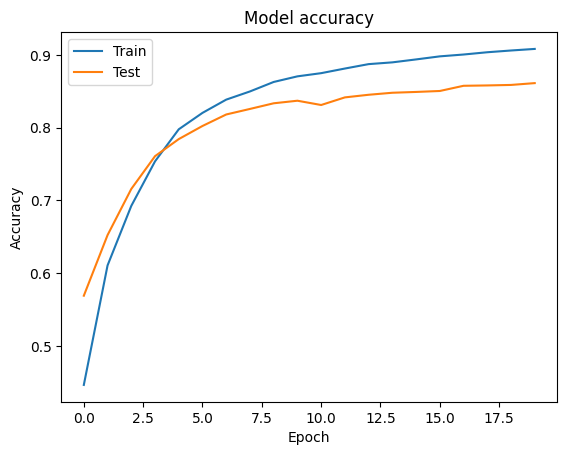

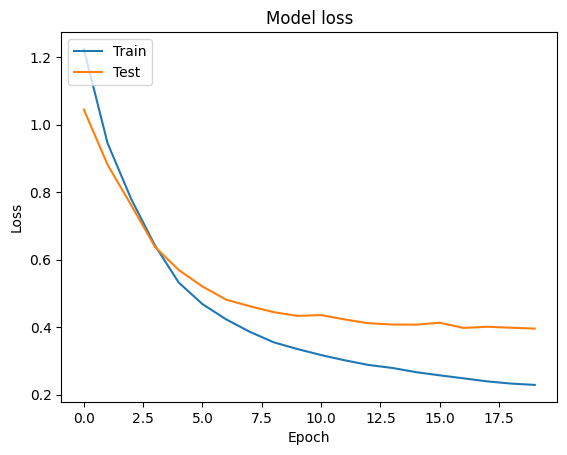

451/451 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step


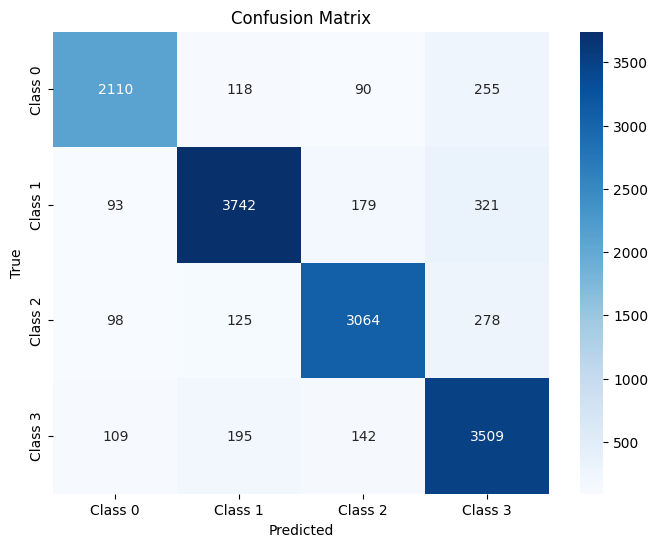

In [108]:

import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('Model loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix



y_pred_probs = model.predict(x_test)
y_pred_labels = np.argmax(y_pred_probs, axis=1)
y_true_labels = np.argmax(y_test_onehot, axis=1)
conf_matrix = confusion_matrix(y_true_labels, y_pred_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1', 'Class 2', 'Class 3'],
            yticklabels=['Class 0', 'Class 1', 'Class 2', 'Class 3'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


In [109]:
loaded_model = model

In [110]:
predictions = loaded_model.predict(x_test)

451/451 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


In [111]:
from sklearn.metrics import classification_report
import numpy as np

# Evaluate the model on test data
loss, accuracy = loaded_model.evaluate(x_test, y_test_onehot, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}\n")

# Detailed Classification Report
y_pred = np.argmax(predictions, axis=1)
y_true = np.argmax(y_test_onehot, axis=1)

# Decode numerical labels back to original text emotions
class_names = [str(cls) for cls in le.classes_]
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

Test Loss: 0.3959
Test Accuracy: 0.8612

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.88      0.82      0.85      2573
    Negative       0.90      0.86      0.88      4335
     Neutral       0.88      0.86      0.87      3565
    Positive       0.80      0.89      0.84      3955

    accuracy                           0.86     14428
   macro avg       0.86      0.86      0.86     14428
weighted avg       0.86      0.86      0.86     14428

